In [ ]:
#IMPORTS

from pathlib import Path
import numpy as np
from PIL import Image
import os
import matplotlib.pyplot as plt
from collections import defaultdict

We have to initially convert the images to numbers
Define Pixels
This is in grayscale
"Digitisation"


Following code is about converting images to numbers, also known as "digitisation".

In [ ]:
IMAGE_DIR = Path("/content/Images")
EXPECTED_SIZE = (180, 200)
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

image_paths = sorted(
    p for p in IMAGE_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in EXTENSIONS
)

print("Images found:", len(image_paths))

if len(image_paths) != 50:
    raise ValueError(f"Expected 50 images, found {len(image_paths)}.")

image_vectors = []

for path in image_paths:
    with Image.open(path) as img:
        img = img.convert("L")

        if img.size != EXPECTED_SIZE:
            raise ValueError(
                f"{path.name}: expected {EXPECTED_SIZE}, got {img.size}"
            )

        image_vectors.append(
            np.asarray(img, dtype=np.float64).reshape(-1)
        )

X = np.column_stack(image_vectors)

np.save("/content/face_data.npy", X)

with open("/content/image_order.txt", "w", encoding="utf-8") as f:
    for path in image_paths:
        f.write(str(path.relative_to(IMAGE_DIR)) + "\n")

print("Digitization complete.")
print("Data matrix shape:", X.shape)
print("Pixel range:", X.min(), "to", X.max())


print(X)

Images found: 50
Digitization complete.
Data matrix shape: (36000, 50)
Pixel range: 0.0 to 255.0
[[70. 70. 73. ... 90. 98. 99.]
 [70. 70. 75. ... 91. 97. 97.]
 [71. 69. 76. ... 93. 94. 94.]
 ...
 [ 1.  2.  2. ... 23. 12. 14.]
 [ 1.  2.  2. ... 31. 23. 23.]
 [ 1.  2.  2. ... 39. 32. 31.]]


### Centering the Data

After digitization, our data matrix $X$ contains 50 images, each represented by a vector of 36,000 pixel values.

$$
X \in \mathbb{R}^{36000 \times 50}
$$

Before performing Principal Component Analysis (PCA), we center the data by subtracting the mean face from every image. This translates the dataset so that its centroid lies at the origin, allowing us to analyze variations around the mean face.

First, we calculate the mean face:

$$
\mu = \frac{1}{N}\sum_{i=1}^{N} x_i
$$

where $N=50$ is the number of images and $x_i$ represents the $i$-th image vector.

We then center each image:

$$
\phi_i = x_i - \mu
$$

Combining all centered images gives the centered data matrix:

$$
A = X - \mu\mathbf{1}^T
$$

where $\mathbf{1}$ is a vector of 50 ones. The resulting matrix retains the dimensions $36000 \times 50$, but the mean of each pixel position across all images is now zero.

Centering is essential because PCA identifies the directions of maximum variance around the mean, which will later be used to construct the eigenfaces.

In [ ]:
N = X.shape[1]

mean_face = np.mean(X, axis=1)
A = X - mean_face[:, np.newaxis]

print("Mean face shape:", mean_face.shape)
print("Centered matrix shape:", A.shape)
print("Maximum absolute row mean:", np.abs(A.mean(axis=1)).max())

Mean face shape: (36000,)
Centered matrix shape: (36000, 50)
Maximum absolute row mean: 1.1084466677857563e-14


The next following code block is done to display the mean face.

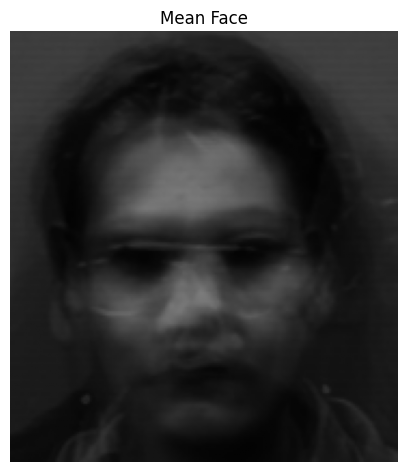

In [ ]:
mean_image = mean_face.reshape(200, 180)

plt.figure(figsize=(5, 6))
plt.imshow(mean_image, cmap="gray", vmin=0, vmax=255)
plt.title("Mean Face")
plt.axis("off")
plt.show()

### Eigenvalue Calculation

We will calculate the matrix \(A^T A\), where \(A\) is the centered data matrix, and obtain its corresponding eigenvalues and eigenvectors.

$$
L=A^TA
$$

Since \(A\) has dimensions \(36000\times50\), the resulting matrix \(L\) has dimensions \(50\times50\). This approach significantly reduces the computational cost compared to directly calculating the covariance matrix in the original pixel space.

We then solve the eigenvalue equation:

$$
Lv_i=\lambda_i v_i
$$

The eigenvalues indicate the amount of variance associated with each principal direction, while the corresponding eigenvectors will be used to construct the eigenfaces.

In [ ]:
L = A.T @ A

eigenvalues, eigenvectors = np.linalg.eigh(L)

idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

print("L shape:", L.shape)
print("Eigenvalues shape:", eigenvalues.shape)
print("Eigenvectors shape:", eigenvectors.shape)
print(eigenvalues)

L shape: (50, 50)
Eigenvalues shape: (50,)
Eigenvectors shape: (50, 50)
[ 8.68939326e+08  5.38411184e+08  3.16740841e+08  2.33203759e+08
  1.73768218e+08  1.44352787e+08  1.05907518e+08  8.73872495e+07
  5.46393864e+07  2.88268975e+07  1.32794630e+07  9.63198471e+06
  9.30690181e+06  8.87201765e+06  8.29730108e+06  7.74167231e+06
  5.50584610e+06  2.66459179e+06  2.42134527e+06  2.17007448e+06
  1.75664480e+06  1.61909522e+06  1.25342232e+06  1.09992255e+06
  1.02049256e+06  9.49021085e+05  9.17750800e+05  7.93280190e+05
  7.11989174e+05  6.68247441e+05  5.97269297e+05  4.62758631e+05
  4.36977097e+05  4.23632859e+05  2.99648633e+05  2.78818836e+05
  2.54930766e+05  1.97361846e+05  1.93499963e+05  1.84511195e+05
  1.78199817e+05  1.69651803e+05  1.60039548e+05  1.51062553e+05
  1.38263345e+05  1.34401575e+05  8.19701320e+04  5.80169689e+04
  3.76525389e+04 -2.76082195e-08]


### Constructing the Eigenfaces

After calculating the eigenvalues and eigenvectors of \(L=A^TA\), we use the eigenvectors to construct the eigenfaces in the original pixel space.

Let \(v_i\) be an eigenvector of \(L\). The corresponding eigenface is obtained by multiplying the centered data matrix \(A\) by \(v_i\):

$$
u_i=Av_i
$$

Since \(A\) has dimensions \(36000\times50\) and \(v_i\) has dimensions \(50\times1\), each resulting eigenface \(u_i\) has dimensions \(36000\times1\).

We then normalize each eigenface to have unit length:

$$
u_i=\frac{u_i}{\|u_i\|}
$$

These eigenfaces represent the principal directions of variation in the original pixel space. They can subsequently be reshaped into images for visualization and used to represent faces with fewer dimensions.

In [ ]:
tol = eigenvalues[0] * 1e-10
valid = eigenvalues > tol

eigenfaces = A @ eigenvectors[:, valid]
eigenfaces /= np.linalg.norm(eigenfaces, axis=0)

scores = A.T @ eigenfaces

print("Number of eigenfaces:", eigenfaces.shape[1])
print("Scores matrix shape:", scores.shape)

Number of eigenfaces: 49
Scores matrix shape: (50, 49)


### Projecting Images onto the Eigenface Basis

After constructing and normalizing the eigenfaces, we project the centered images onto the eigenface basis to obtain a compact representation of each face.

Let \(Q\) be the matrix whose columns are the normalized eigenfaces. The projection is calculated as:

$$
S=A^TQ
$$

where \(A\) is the centered data matrix and \(Q\) is the eigenface matrix.

Since \(A^T\in\mathbb{R}^{50\times36000}\) and \(Q\in\mathbb{R}^{36000\times k}\), the resulting score matrix is:

$$
S\in\mathbb{R}^{50\times k}
$$

Each row represents one image, while each column represents its coordinate along an eigenface direction. These coordinates, called *scores*, describe how much each eigenface contributes to the representation of an image.

Instead of representing each image using all 36,000 pixel values, we can represent it using its \(k\) scores. This reduces the dimensionality of the data while retaining information captured by the selected eigenfaces. These compact representations can later be used to compare faces for recognition.

In [ ]:
scores = A.T @ eigenfaces

print("Scores matrix shape:", scores.shape)
print(scores)

Scores matrix shape: (50, 49)
[[-4.42110584e+03 -4.02292794e+03  9.80669448e+02 ... -1.59550677e+00
  -1.61767508e-01 -3.85219866e-01]
 [-4.73975270e+03 -3.95734881e+03  3.81246890e+02 ... -2.64073008e-01
  -6.45168223e-01 -7.21057452e-01]
 [-4.69744969e+03 -3.89477143e+03  4.49939200e+02 ...  2.37785044e-01
   8.90019654e-02  2.36119766e+00]
 ...
 [ 4.37895033e+03  4.76221200e+03 -1.11487440e+03 ... -1.97636013e-01
  -1.34656708e+00  1.86742307e-02]
 [ 4.35508642e+03  4.77678324e+03 -1.13342517e+03 ... -3.78627032e-01
   2.83482222e-01  2.18600418e-01]
 [ 4.32582636e+03  4.62199843e+03 -1.16701088e+03 ...  5.83280769e-01
   4.23413764e-01 -9.97784193e-02]]


### Principal Component Selection

Although centering 50 images gives us at most 49 meaningful principal components, retaining all of them is not always necessary. Principal Component Analysis (PCA) allows us to reduce the dimensionality further by selecting the components that explain the greatest proportion of variance in the dataset.

Since the eigenvalues are sorted in descending order, the first components capture the greatest variance. The explained variance ratio of the \(i\)-th component is:

$$
r_i=\frac{\lambda_i}{\sum_{j=1}^{49}\lambda_j}
$$

The cumulative explained variance of the first \(k\) components is:

$$
R_k=\frac{\sum_{i=1}^{k}\lambda_i}{\sum_{j=1}^{49}\lambda_j}
$$

We can select the smallest number of components needed to reach a chosen variance threshold, such as 95%. This produces a more compact representation of each face while retaining most of the variation present in the training data.

In [ ]:
tol = eigenvalues[0] * 1e-10
positive_eigenvalues = eigenvalues[eigenvalues > tol]

explained_variance = (
    positive_eigenvalues / positive_eigenvalues.sum()
)

cumulative_variance = np.cumsum(explained_variance)

k = np.searchsorted(cumulative_variance, 0.95) + 1

print("Meaningful components:", len(positive_eigenvalues))
print("Components for 95% variance:", k)
print("Variance retained:", cumulative_variance[k - 1])

Meaningful components: 49
Components for 95% variance: 9
Variance retained: 0.9567941594437179


### Image Reconstruction Using Principal Components

After selecting the first \(k\) principal components, we can reconstruct an approximation of each original image using its score vector and the corresponding eigenfaces.

The score vector of the \(i\)-th centered image is:

$$
s_i=Q_k^T(x_i-\mu)
$$

We reconstruct the image by combining its scores with the selected eigenfaces and adding the mean face back:

$$
\hat{x}_i=\mu+Q_k s_i
$$

The reconstructed vector can then be reshaped into the original image dimensions of \(200\times180\) pixels.

Reconstruction allows us to examine how much information is preserved when the original 36,000 pixel values are represented using only \(k\) principal components. This also helps us understand the trade-off between dimensionality reduction and information loss.

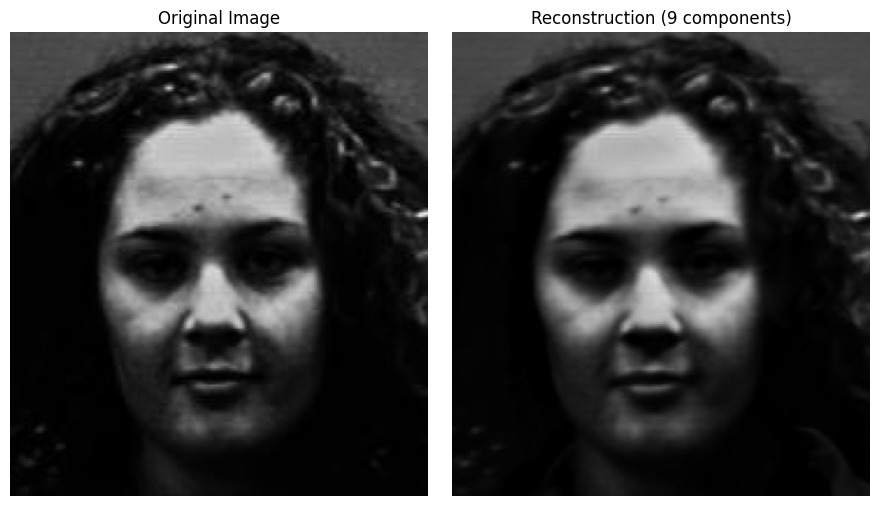

In [ ]:
Q_k = eigenfaces[:, :k]

scores = A.T @ Q_k

i = 0

reconstructed = mean_face + Q_k @ scores[i, :]
original_image = X[:, i].reshape(200, 180)
reconstructed_image = reconstructed.reshape(200, 180)

fig, axes = plt.subplots(1, 2, figsize=(9, 5))

axes[0].imshow(original_image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(
    reconstructed_image, cmap="gray", vmin=0, vmax=255
)
axes[1].set_title(f"Reconstruction ({k} components)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

### Training and Testing Split

To evaluate our face recognition system, we divide the dataset into training and testing sets. Since the dataset contains 10 people with 5 images each, we select 4 images per person for training and reserve 1 image per person for testing.

This produces 40 training images and 10 testing images. The training set is used to calculate the mean face, construct the eigenfaces, and determine the principal components. The testing set is used to evaluate whether the system can correctly identify previously unseen images.

To prevent data leakage, all preprocessing and PCA calculations must be performed using only the training set. The testing images are projected onto the eigenface basis learned from the training images, and their predicted identities are compared with their actual identities to measure recognition accuracy.

In [ ]:
labels = [
    path.stem.split(".")[1]
    for path in image_paths
]

groups = defaultdict(list)

for i, label in enumerate(labels):
    groups[label].append(i)

if len(groups) != 10 or any(len(indices) != 5 for indices in groups.values()):
    raise ValueError("Expected 10 people with 5 images each.")

train_indices = []
test_indices = []

for label, indices in sorted(groups.items()):
    indices = sorted(indices, key=lambda i: image_paths[i].name)
    train_indices.extend(indices[:4])
    test_indices.append(indices[4])

X_train = X[:, train_indices]
X_test = X[:, test_indices]

y_train = np.array(labels)[train_indices]
y_test = np.array(labels)[test_indices]

print("Training matrix:", X_train.shape)
print("Testing matrix:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training matrix: (36000, 40)
Testing matrix: (36000, 10)
Training labels: (40,)
Testing labels: (10,)


### Principal Component Analysis on the Training Set

Now that the dataset has been divided into training and testing sets, we perform PCA using only the training images. This prevents data leakage, ensuring that the test images do not influence the eigenface basis.

First, we calculate the mean face from the training set:

$$
\mu_{\text{train}}=\frac{1}{N_{\text{train}}}\sum_{i=1}^{N_{\text{train}}}x_i
$$

We then center the training data:

$$
A_{\text{train}}=X_{\text{train}}-\mu_{\text{train}}\mathbf{1}^T
$$

Next, we construct the smaller matrix:

$$
L=A_{\text{train}}^TA_{\text{train}}
$$

Since there are 40 training images, \(L\) is a \(40\times40\) matrix. We calculate its eigenvalues and eigenvectors, sort them in descending order, and use the leading eigenvectors to construct the eigenfaces.

These eigenfaces form the basis onto which both training and testing images will be projected.

In [ ]:
N_train = X_train.shape[1]

mean_train = np.mean(X_train, axis=1)
A_train = X_train - mean_train[:, np.newaxis]

L_train = A_train.T @ A_train

eigenvalues_train, eigenvectors_train = np.linalg.eigh(L_train)

idx = np.argsort(eigenvalues_train)[::-1]
eigenvalues_train = eigenvalues_train[idx]
eigenvectors_train = eigenvectors_train[:, idx]

tol = max(eigenvalues_train[0], 0) * 1e-10
valid = eigenvalues_train > tol

eigenvalues_train = eigenvalues_train[valid]
eigenvectors_train = eigenvectors_train[:, valid]

eigenfaces_train = A_train @ eigenvectors_train
eigenfaces_train /= np.linalg.norm(eigenfaces_train, axis=0)

print("Training matrix:", A_train.shape)
print("Eigenvalue matrix:", L_train.shape)
print("Number of valid eigenfaces:", eigenfaces_train.shape[1])

Training matrix: (36000, 40)
Eigenvalue matrix: (40, 40)
Number of valid eigenfaces: 39


### Selecting Principal Components

Each eigenface represents a direction of variation in the training images. Eigenfaces with larger eigenvalues explain more of the variation.

We will retain enough eigenfaces to explain at least **95% of the total variance**.

The cumulative explained variance is

$$
C_k=\frac{\sum_{i=1}^{k}\lambda_i}
{\sum_{i=1}^{r}\lambda_i}
$$

where \(\lambda_i\) is the \(i\)-th eigenvalue. We choose the smallest \(k\) for which \(C_k\geq 0.95\).

Number of eigenfaces selected: 9
Explained variance: 96.94 %


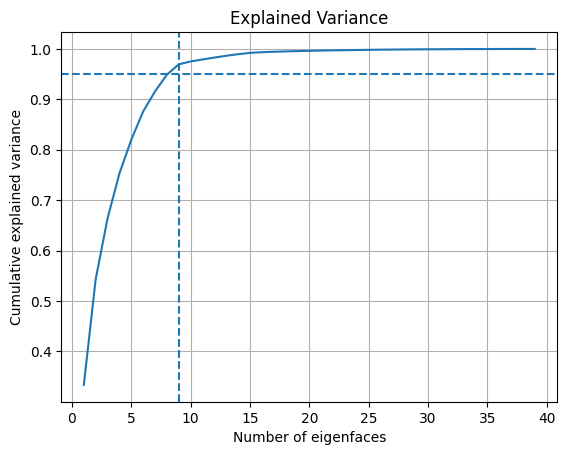

In [ ]:
explained_variance = eigenvalues_train / eigenvalues_train.sum()
cumulative_variance = np.cumsum(explained_variance)

k = np.searchsorted(cumulative_variance, 0.95) + 1

print("Number of eigenfaces selected:", k)
print("Explained variance:", round(cumulative_variance[k - 1] * 100, 2), "%")

plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance)
plt.axhline(y=0.95, linestyle="--")
plt.axvline(x=k, linestyle="--")
plt.xlabel("Number of eigenfaces")
plt.ylabel("Cumulative explained variance")
plt.title("Explained Variance")
plt.grid(True)
plt.show()

### Image Projection

We project each image onto the first \(k\) eigenfaces to represent it using fewer dimensions.

Let \(Q_k\) contain the selected eigenfaces. The training and test scores are

$$
S_{\text{train}}=A_{\text{train}}^TQ_k
$$

$$
S_{\text{test}}=(X_{\text{test}}-\mu_{\text{train}})^TQ_k
$$

Each row of a score matrix represents one image in the reduced-dimensional space. The training mean and eigenfaces are used for both sets to avoid data leakage.

In [ ]:
Q_k = eigenfaces_train[:, :k]

A_test = X_test - mean_train[:, np.newaxis]

scores_train = A_train.T @ Q_k
scores_test = A_test.T @ Q_k

print("Training scores:", scores_train.shape)
print("Test scores:", scores_test.shape)

Training scores: (40, 9)
Test scores: (10, 9)


### Face Recognition

For each test image, we calculate its Euclidean distance from every training image in the reduced-dimensional space.

$$
d(x,y)=\sqrt{\sum_{j=1}^{k}(x_j-y_j)^2}
$$

The training image with the smallest distance is selected as the match. Its identity becomes the predicted identity of the test image.

Finally, we compare the predicted identities with the actual identities to calculate accuracy.

In [ ]:
predictions = []

for test_score in scores_test:
    distances = np.linalg.norm(scores_train - test_score, axis=1)
    nearest = np.argmin(distances)
    predictions.append(y_train[nearest])

predictions = np.array(predictions)

accuracy = np.mean(predictions == y_test) * 100

print("Actual identities:   ", y_test)
print("Predicted identities:", predictions)
print(f"Recognition accuracy: {accuracy:.2f}%")

Actual identities:    ['anpage' 'asamma' 'drbost' 'ekavaz' 'klclar' 'pacole' 'pspliu' 'rsanti'
 'sjbeck' 'skumar']
Predicted identities: ['anpage' 'asamma' 'drbost' 'ekavaz' 'klclar' 'pacole' 'pspliu' 'rsanti'
 'sjbeck' 'skumar']
Recognition accuracy: 100.00%


Results.

In [ ]:
for i in range(len(y_test)):
    result = "Correct" if predictions[i] == y_test[i] else "Incorrect"
    print(
        f"Test image {i + 1}: "
        f"Actual = {y_test[i]}, "
        f"Predicted = {predictions[i]}, "
        f"{result}"
    )

Test image 1: Actual = anpage, Predicted = anpage, Correct
Test image 2: Actual = asamma, Predicted = asamma, Correct
Test image 3: Actual = drbost, Predicted = drbost, Correct
Test image 4: Actual = ekavaz, Predicted = ekavaz, Correct
Test image 5: Actual = klclar, Predicted = klclar, Correct
Test image 6: Actual = pacole, Predicted = pacole, Correct
Test image 7: Actual = pspliu, Predicted = pspliu, Correct
Test image 8: Actual = rsanti, Predicted = rsanti, Correct
Test image 9: Actual = sjbeck, Predicted = sjbeck, Correct
Test image 10: Actual = skumar, Predicted = skumar, Correct
